# Notebook 02 — Data Cleaning & Preprocessing

**Project:** Student Wellbeing & Mental Health Risk — Educational Classification Prototype  
**Notebook goal:** Prepare the data safely for training, with a reproducible pipeline and an independent 80/20 test split.

> **Important:** This is a learning project, **not** a diagnosis, clinical screening tool, disciplinary system, or student-selection tool. Predictions are statistical estimates from a dataset, not judgments about real students.

## How to use this notebook

1. Read the **What to do** and **Why it matters** sections.
2. Write **your own Python code** in each blank code cell directly below the instructions.
3. Check the **Example of expected output** (illustrative only; your values will differ).
4. Write your findings in the **Your interpretation** prompts before moving on.

**You will learn to:**
- Keep the original dataset unchanged and create an 80/20 split.
- Justify missing-value, outlier, encoding, and scaling choices.
- Prevent information leakage during preprocessing and resampling.
- Prepare reusable transformations for model training.


---

## 1. Define features, target, and excluded columns

### What to do
- Load the dataset and use the target selected in Notebook 01.
- Separate **X (features)** from **y (target)**.
- Exclude IDs, identifiers, data collected after the outcome, and any fields that leak the answer.
- Explain each exclusion.

### Why it matters
A feature that contains the answer can make a model appear successful while failing on new data.

### Example of expected output

**Illustrative:** `X shape: (2000, 10) | y shape: (2000,)`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Target is not in X.
- [ ] Identifiers and leakage fields have been reviewed.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path



FILE_PATH = "/home/mestry/Documents/youcode/Pr-diction-du-risque-de-sant-mentale-chez-les-tudiants/student-mental-health/data/raw/student_mental_health.csv"
PROCESS_PATH = "/home/mestry/Documents/youcode/Pr-diction-du-risque-de-sant-mentale-chez-les-tudiants/student-mental-health/data/processed"

PROCESS_PATH = Path(PROCESS_PATH)
PROCESS_PATH.mkdir(parents=True, exist_ok=True)

try:
    data = pd.read_csv(FILE_PATH)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file at {FILE_PATH} was not found.")

dataSet = pd.read_csv(FILE_PATH)


X = dataSet.drop(columns=["Student_ID","Mental_Health_Risk"])
y = dataSet["Mental_Health_Risk"]

print("shape of (X):", X.shape)
print("shape of (y):", y.shape)


Dataset loaded successfully.
shape of (X): (2000, 15)
shape of (y): (2000,)


### Your interpretation (write in your own words)
Which columns did you exclude and why?

**My notes:** `Student_ID` is excluded because it is an identifier with no meaningful predictive signal and could cause memorization. `Mental_Health_Risk` is the target, so it is kept in `y` and excluded from `X` to prevent target leakage. All remaining columns are candidate input features.


---

## 2. Split train/test BEFORE learned transformations

### What to do
- Split into **80% training** and **20% test**.
- Set a random seed for reproducibility.
- Consider stratification when appropriate for a classification target.
- Print the sizes and label distributions.

### Why it matters
The test set must remain independent and untouched until final evaluation.

### Example of expected output

**Illustrative:** `Training: 1600 rows | Test: 400 rows`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Correct 80/20 split.
- [ ] Random seed documented.
- [ ] Test set reserved for Notebook 04.

### Watch out
Do not impute, scale, oversample, or select features using the entire dataset before splitting.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [69]:
from sklearn.model_selection import train_test_split

train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("shape of (train_X):", train_X.shape)
print("shape of (test_X):", test_X.shape)
print("shape of (train_y):", train_y.shape)
print("shape of (test_y):", test_y.shape)

shape of (train_X): (1600, 15)
shape of (test_X): (400, 15)
shape of (train_y): (1600,)
shape of (test_y): (400,)


---

## 3. Define transparent data quality rules

### What to do
- Decide how to handle known invalid categories, impossible ranges, and duplicates.
- Explain whether each rule is a fixed domain rule or a statistic learned from training data.
- Make sure any learned rule is based only on training folds.

### Why it matters
Consistent decisions prevent accidental bias and make the workflow reproducible.

### Example of expected output

**Illustrative rule:** `sleep_hours outside a justified valid range → mark for review; do not auto-delete`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Each cleaning decision is written down.
- [ ] Rules apply consistently to validation/test rows.

### Watch out
Do not drop a test row just because it is inconvenient. For individual predictions, validate inputs and show clear errors.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [70]:

rules = {
    "Age": (0, 120),
    "Year_of_Study": (1, 5),
    "Sleep_Hours": (0, 24),
    "Study_Hours_Per_Week": (0, 168),
    "Social_Media_Hours": (0, 24),
    "Screen_Time_Hours": (0, 24),
    "GPA": (0, 4),
    "Financial_Stress": (0, 10),
    "Family_Support": (0, 10),
    "Attendance_Rate": (0, 100),
}

print("Numeric range validation (training partition):")
for col, (minimum, maximum) in rules.items():
    invalid = train_X[col].notna() & ~train_X[col].between(minimum, maximum)
    print(f"{col}: {int(invalid.sum())} invalid values; observed range {train_X[col].min():.2f} to {train_X[col].max():.2f}")

print(f"\nDuplicate feature rows in training partition: {int(train_X.duplicated().sum())}")
print("\nMissing values in training partition:")
display(train_X.isna().sum().to_frame("missing_count"))

categorical_cols = train_X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("Categorical values in training partition (including missing values):")
for col in categorical_cols:
    print(f"{col}: {train_X[col].value_counts(dropna=False).to_dict()}")


Numeric range validation (training partition):
Age: 0 invalid values; observed range 17.00 to 28.00
Year_of_Study: 0 invalid values; observed range 1.00 to 5.00
Sleep_Hours: 0 invalid values; observed range 3.60 to 10.00
Study_Hours_Per_Week: 0 invalid values; observed range 2.40 to 38.30
Social_Media_Hours: 0 invalid values; observed range 2.10 to 10.00
Screen_Time_Hours: 0 invalid values; observed range 3.30 to 14.00
GPA: 0 invalid values; observed range 1.50 to 3.66
Financial_Stress: 0 invalid values; observed range 1.40 to 10.00
Family_Support: 0 invalid values; observed range 1.70 to 9.90
Attendance_Rate: 0 invalid values; observed range 54.40 to 100.00

Duplicate feature rows in training partition: 0

Missing values in training partition:


,missing_count
Age,0
Gender,0
Year_of_Study,0
Sleep_Hours,54
Study_Hours_Per_Week,0
GPA,36
Social_Media_Hours,48
Screen_Time_Hours,0
Physical_Activity,0
Financial_Stress,76


Categorical values in training partition (including missing values):
Gender: {'Female': 779, 'Male': 746, 'Non-binary': 75}
Physical_Activity: {'Moderate': 742, 'Low': 539, 'High': 319}
Part_Time_Job: {'No': 1029, 'Yes': 571}
Diet_Quality: {'Average': 687, 'Poor': 476, 'Good': 382, nan: 55}
Previous_Mental_Health_History: {'No': 1140, 'Yes': 460}


### Your interpretation (write in your own words)
Why is this cleaning approach suitable for this column?

**My notes:** The ranges are explicit domain checks: age, study year, hours, GPA, stress/support scores, and attendance have natural limits. The checks report violations rather than silently deleting rows, so unusual records can be reviewed consistently. The categorical value counts document the observed categories and missingness, while duplicate rows are counted so repeated records are visible before modeling. These rules are applied for validation only; the train-fitted preprocessing pipeline handles missing values without learning from the test partition.


---

## 4. Plan missing-value imputation

### What to do
- Separate numerical and categorical columns.
- Select an imputation method for each group (for example median and most frequent).
- Investigate missingness patterns and justify choices.
- Ensure imputer statistics are learned from training data only.

### Why it matters
Filling missing values lets models work with incomplete records while preventing leakage.

### Example of expected output

**Illustrative:** `numeric: median | categorical: most frequent`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Numerical and categorical strategies defined.
- [ ] Missing values are handled by a fitted transformer.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [71]:

numeric_cols = train_X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = train_X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Training numeric missing values:", int(train_X[numeric_cols].isna().sum().sum()))
print("Training categorical missing values:", int(train_X[categorical_cols].isna().sum().sum()))
print("Test numeric missing values:", int(test_X[numeric_cols].isna().sum().sum()))
print("Test categorical missing values:", int(test_X[categorical_cols].isna().sum().sum()))


Numeric columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']
Training numeric missing values: 289
Training categorical missing values: 55
Test numeric missing values: 61
Test categorical missing values: 14


### Your interpretation (write in your own words)
Why is your chosen method better than simply deleting all incomplete rows?

**My notes:** Median imputation for numeric features is robust to skew and is fitted only on `train_X`, while most-frequent imputation gives categorical models a valid observed category and is also fitted only on training data. This keeps usable rows, avoids changing the test set based on its own statistics, and makes the same decisions reusable for future predictions. The imputers are implemented inside the final pipeline in Step 9, so no learned values leak across the split.


---

## 5. Decide how to handle outliers

### What to do
- Use IQR, Z-score, or justified domain thresholds to identify unusual values.
- Compare approaches and decide whether to keep, cap, or transform values.
- If limits depend on the data, fit them on training data only.

### Why it matters
Extreme values may be errors or valid reports; blindly deleting them can distort the sample.

### Example of expected output

**Illustrative:** `3 values flagged for review; no rows deleted`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Outlier strategy is documented.
- [ ] No inference from held-out test statistics.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

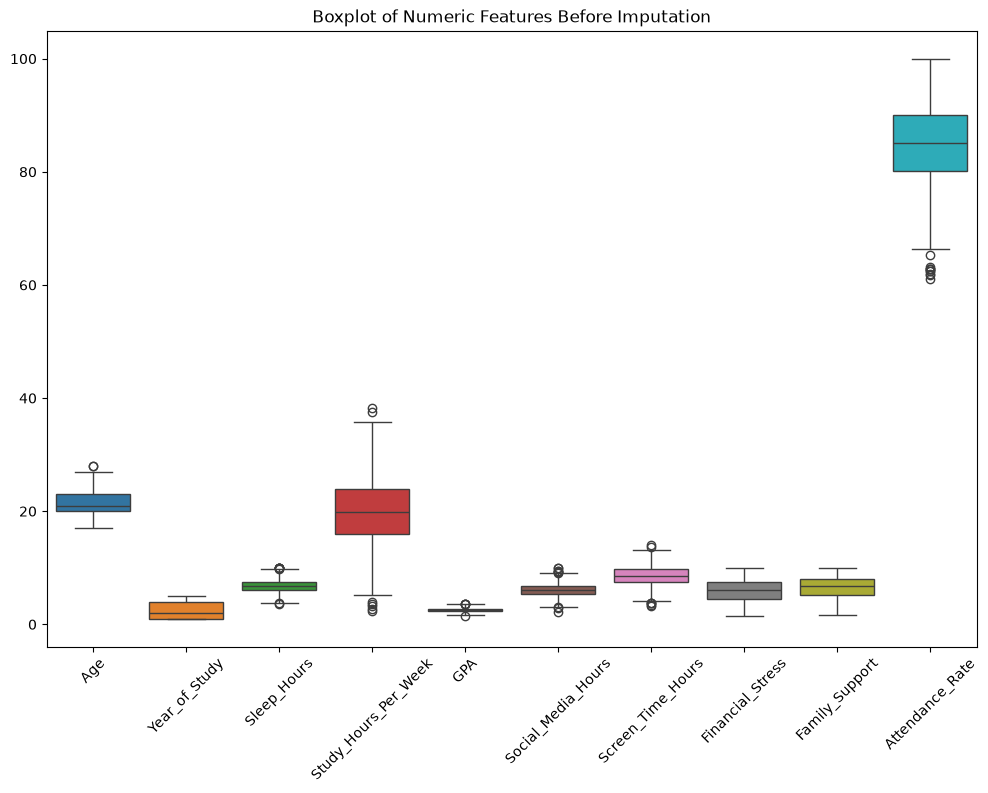

1273    62.8
906     62.8
Name: Attendance_Rate, dtype: float64


,Feature,Outliers,Min Distance,Max Distance,Max Outlier Value,Min Outlier Value,max outlier from upper bound Distance,max outlier from lower bound Distance
0,Age,2,7.00,7.0,28.00,28.0,0.50,NaN
1,Sleep_Hours,9,3.00,3.3,10.00,3.6,0.25,0.15
2,Study_Hours_Per_Week,7,15.90,18.5,38.30,2.4,2.30,1.60
3,GPA,5,0.97,1.1,3.66,1.5,0.14,0.10
4,Social_Media_Hours,10,3.00,4.0,10.00,2.1,0.95,0.95
5,Screen_Time_Hours,7,4.70,5.5,14.00,3.3,0.85,0.65
6,Attendance_Rate,10,19.80,24.0,65.30,61.1,NaN,4.25


In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.boxplot(data=train_X[numeric_cols])
plt.title("Boxplot of Numeric Features Before Imputation")
plt.xticks(rotation=45)
plt.show()


outliers_info = []

for col in numeric_cols:
    q1 = train_X[col].quantile(0.25)
    q3 = train_X[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = train_X[col][
        (train_X[col] < lower) | (train_X[col] > upper)
    ]

    median = train_X[col].median()

    if len(outliers) > 0:
        distances = abs(outliers - median)
        ditances_upper = abs(outliers[outliers > upper] - upper)
        ditances_lower = abs(outliers[outliers < lower] - lower)

        outliers_info.append({
            "Feature": col,
            "Outliers": len(outliers),
            "Min Distance": distances.min(),
            "Max Distance": distances.max(),
            "Max Outlier Value": outliers.max(),
            "Min Outlier Value": outliers.min(),
            'max outlier from upper bound Distance': ditances_upper.max() if not ditances_upper.empty else np.nan,
            'max outlier from lower bound Distance': ditances_lower.max() if not ditances_lower.empty else np.nan
        })

outliers_df = pd.DataFrame(outliers_info)



replacement = train_X["Attendance_Rate"][train_X["Attendance_Rate"] > 62.5].min()

train_X.loc[[1273, 906], "Attendance_Rate"] = replacement

print(train_X.loc[[1273, 906], "Attendance_Rate"])

display(outliers_df)




### Your interpretation (write in your own words)
What would be the risk of deleting every unusual student record?

**My notes:** An IQR outlier is unusual relative to this sample, not automatically invalid. Deleting every unusual student could remove legitimate experiences, reduce representation of minority patterns, and bias the model toward average students. The domain checks found no invalid values in the observed ranges, so the plausible outliers are retained; the pipeline imputes missing values but does not trim valid observations.


---

## 6. Encode categorical variables

### What to do
- Identify categorical columns.
- Choose one-hot or another encoding suited to your models.
- Ensure unseen categories in new records do not crash the pipeline.

### Why it matters
Most scikit-learn classifiers require numerical representations.

### Example of expected output

**Illustrative:** `study_mode → study_mode_online, study_mode_on_campus`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Categorical features become numerical.
- [ ] Unknown categories have a defined policy.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [73]:
print("Categorical columns will be encoded by OneHotEncoder(handle_unknown='ignore') in the Step 9 pipeline:")
print(categorical_cols)
print("Dummy encoding is handled inside the pipeline, so train/test columns remain aligned and unseen test categories are handled safely.")


Categorical columns will be encoded by OneHotEncoder(handle_unknown='ignore') in the Step 9 pipeline:
['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']
Dummy encoding is handled inside the pipeline, so train/test columns remain aligned and unseen test categories are handled safely.


### Your interpretation (write in your own words)
Why should encoding be fitted on training data?

**My notes:** Fitting the encoder on training data prevents test-set categories and frequencies from influencing the learned representation. `handle_unknown="ignore"` keeps transformation valid when a future or test row contains a category not seen during training, while the pipeline guarantees identical feature columns for train and test data.


---

## 7. Scale numerical variables

### What to do
- Decide whether standardization or normalization is suitable.
- Use scaling inside the fitted preprocessing pipeline.
- Explain which classifiers are sensitive to feature scale.

### Why it matters
Some methods (e.g., logistic regression and SVM) can be influenced by large differences in scale.

### Example of expected output

**Illustrative:** `scaled training feature: mean approximately 0; standard deviation approximately 1`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Scaling choice documented.
- [ ] Scaler learns parameters only on train folds.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [74]:
print("StandardScaler is applied only to numeric columns inside the Step 9 pipeline.")
print("There is no standalone scaling step, so its means and standard deviations are learned from training data only.")


StandardScaler is applied only to numeric columns inside the Step 9 pipeline.
There is no standalone scaling step, so its means and standard deviations are learned from training data only.


### Your interpretation (write in your own words)
Which model types might need scaling more than tree-based models?

**My notes:** Distance- and magnitude-sensitive models such as logistic regression, support vector machines, k-nearest neighbors, and neural networks can be affected when features use different units, so standardization helps them compare features fairly. Tree-based models split on thresholds and generally do not require scaling, but using one consistent numeric preprocessing pipeline keeps model comparisons reproducible.


---

## 8. Address class imbalance carefully

### What to do
- Review the training-label distribution from Notebook 01.
- Decide whether imbalance requires class weights or training-only resampling.
- If using SMOTE, apply it **inside training cross-validation folds** (e.g., with an imbalanced-learn pipeline).
- Do not alter the untouched test set.

### Why it matters
Resampling before validation leaks information and can exaggerate model performance.

### Example of expected output

**Illustrative:** `train: 70/30 → balanced within each training fold; test: original ratio`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Imbalance strategy is justified.
- [ ] Resampling happens only within training folds.
- [ ] Test distribution remains original.

### Watch out
SMOTE is not always appropriate for raw mixed categorical data; consider SMOTENC or class weights when needed.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [75]:
print("Training label distribution:")
print(train_y.value_counts())
print("\nTest label distribution:")
print(test_y.value_counts())

train_proportions = train_y.value_counts(normalize=True).sort_index()
print("\nTraining label proportions:")
print(train_proportions)
print("\nSMOTE decision: not used. The classes are approximately balanced, so synthetic oversampling is unnecessary and would add complexity. The original stratified training data is retained.")


Training label distribution:
Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64

Test label distribution:
Mental_Health_Risk
High      136
Medium    132
Low       132
Name: count, dtype: int64

Training label proportions:
Mental_Health_Risk
High      0.34
Low       0.33
Medium    0.33
Name: proportion, dtype: float64

SMOTE decision: not used. The classes are approximately balanced, so synthetic oversampling is unnecessary and would add complexity. The original stratified training data is retained.


### Your interpretation (write in your own words)
Would class weights be a simpler alternative in this dataset?

**My notes:** Class weights could be a simple safeguard if a later training split or model shows meaningful imbalance, but the current stratified training labels are approximately balanced. Therefore neither class weights nor SMOTE is needed for this preparation notebook; model-specific weighting can be evaluated later without altering the leakage-safe feature pipeline.


---

## 9. Build and verify the final pipeline

### What to do
- Combine numerical and categorical transformations (for example with ColumnTransformer).
- Attach preprocessing to each model through a Pipeline; include resampling only if justified.
- Fit on training data; transform validation folds and later test data with the same fitted objects.
- Confirm output shape and absence of missing/invalid values.

### Why it matters
A single reproducible pipeline makes consistent transformations possible during training and in Streamlit.

### Example of expected output

**Illustrative:** `raw features: 10 | transformed features: 17 | unexpected NaN: 0`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Pipeline is reproducible.
- [ ] No leakage from test set.
- [ ] Expected transformed features verified.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [76]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

X_train_num = numeric_pipeline.fit_transform(train_X[numeric_cols])
X_test_num = numeric_pipeline.transform(test_X[numeric_cols])

X_train_cat = categorical_pipeline.fit_transform(train_X[categorical_cols])
X_test_cat = categorical_pipeline.transform(test_X[categorical_cols])

X_train_num = pd.DataFrame(X_train_num, columns=numeric_cols, index=train_X.index)
X_test_num = pd.DataFrame(X_test_num, columns=numeric_cols, index=test_X.index)

cat_cols = categorical_pipeline.named_steps["encoder"].get_feature_names_out(categorical_cols)

X_train_cat = pd.DataFrame(X_train_cat, columns=cat_cols, index=train_X.index)
X_test_cat = pd.DataFrame(X_test_cat, columns=cat_cols, index=test_X.index)

X_train_final = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_final = pd.concat([X_test_num, X_test_cat], axis=1)

print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

X_train_final.to_csv(PROCESS_PATH / "X_train.csv", index=False)
X_test_final.to_csv(PROCESS_PATH / "X_test.csv", index=False)

train_y.to_csv(PROCESS_PATH / "y_train.csv", index=False)
test_y.to_csv(PROCESS_PATH / "y_test.csv", index=False)

print("Datasets saved successfully!")

Train shape: (1600, 23)
Test shape: (400, 23)
Datasets saved successfully!


### Your interpretation (write in your own words)
Summarize the sequence of transformations in plain English.

**My notes:** The original data is split first with an 80/20 stratified split. The `ColumnTransformer` then learns numeric medians from training data, imputes numeric values, and standardizes them. Separately, it learns the most frequent training category, imputes categorical values, and one-hot encodes categories while ignoring unknown categories. The fitted transformer is reused unchanged for the test data, producing matching shapes with no missing values and avoiding leakage.


---

## Final preprocessing deliverables

- [x] Documented X/y and exclusions
- [x] Independent 80/20 train/test split
- [x] Validated ranges, categories, missing values, and duplicates
- [x] Justified imputation and outlier strategy
- [x] Encoding and scaling inside a leakage-safe pipeline
- [x] Correct training-only class-imbalance approach (no SMOTE for approximately balanced classes)
- [x] Reusable preprocessing pipeline with verified transformed shapes and no missing values

**Next notebook:** `03_training.ipynb` — train three candidate classifiers and compare them using validation / cross-validation on the training portion only.
